# Part 1. Modeling of Carenary Curve
#### It implements a full cycle from defining the geometry of the catenary curve analytically to constructing a PSF image.

*Note*

1. Using the N parameter, we determine the number of cell layers, the more of them, the better the light collection.
2. The parameter N must be even., 0/2/4 etc.
3. M - defines the number of orders. The more of them there are, the more light is collected. The long-range orders become very small.
4. L_center - Determines the number of curves for the first order (most intensive)

/home/eduser/miniconda3/envs/pytdml/lib/python3.8/site-packages/meep/simulation.py:6217: RuntimeWarning: quiet has been deprecated; use the Verbosity class instead
  warnings.warn(


substrait begin in -2.25 and end -1.25
atom begin in -1.25 and end 0.25
flux_center begin in 3.85
at_center is -0.5
sub_center is -1.75
resolution is 1


  0%|          | 0/9 [00:00<?, ?it/s]

Circle 0
Section: 0 : [25.31610026 28.98291054  0.          0.        ]
Section: 1 : [ 0.         20.09380377  0.          0.        ]
Circle 1
Section: 0 : [287.23880845 295.83519066 286.26619067 296.79658972]
Section: 1 : [291.49862136   0.         288.49868136 294.58361994]
Circle 2
Section: 0 : [408.68963288 415.92189994 407.87247461 416.72979256]
Section: 1 : [412.37196801   0.         409.75264286 414.86547132]
Circle 3
Section: 0 : [501.70041274 508.24140066 500.96893455 508.97145488]
Section: 1 : [505.08977045   0.         502.66146783 507.28668224]
Circle 4
Section: 0 : [580.0530128  586.1320672  579.36986992 586.81272806]
Section: 1 : [583.09782202   0.         580.94323489 585.24418216]
Circle 5
Section: 0 : [649.04289011 654.7931944  648.39778148 655.43622655]
Section: 1 : [651.91517336   0.         649.88609425 653.95210516]
Circle 6
Section: 0 : [711.39401446 716.88882998 710.77839371 717.50227192]
Section: 1 : [714.0682569    0.         712.1982578  716.08680614]
Circle 

 11%|█         | 1/9 [00:00<00:03,  2.51it/s]Warning: grid volume is not an integer number of pixels; cell size will be rounded to nearest pixel.


Circle 9
Section: 0 : [872.15937924 877.12265313 871.60526296 877.67778029]
Section: 1 : [874.59787527   0.         872.88657445 876.39899023]
Checked




 44%|████▍     | 4/9 [00:00<00:00,  6.04it/s]Warning: grid volume is not an integer number of pixels; cell size will be rounded to nearest pixel.


FloatProgress(value=0.0, description='0% done ', max=16.0)

 56%|█████▌    | 5/9 [00:04<00:04,  1.03s/it]

Izyx_fp_max:0.16166402978612354


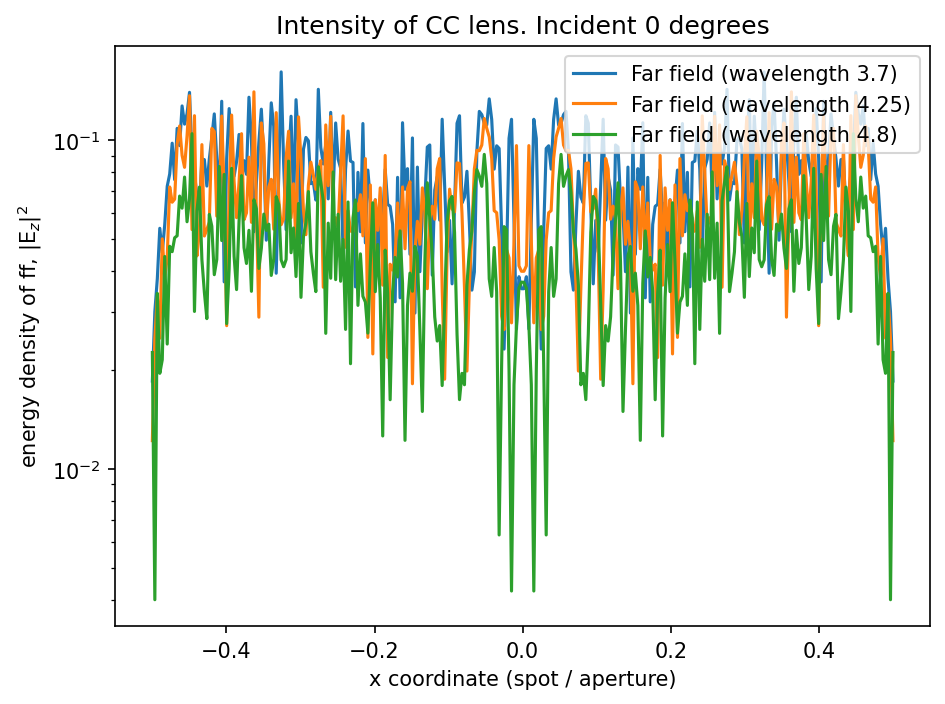

 67%|██████▋   | 6/9 [00:24<00:20,  6.71s/it]

max Ez = 0.08121138528895266 , max Ey = 0.08040707769259667, max Ex = 0.00014242832763223406
shape of x is (300,) shape of I is (300,)


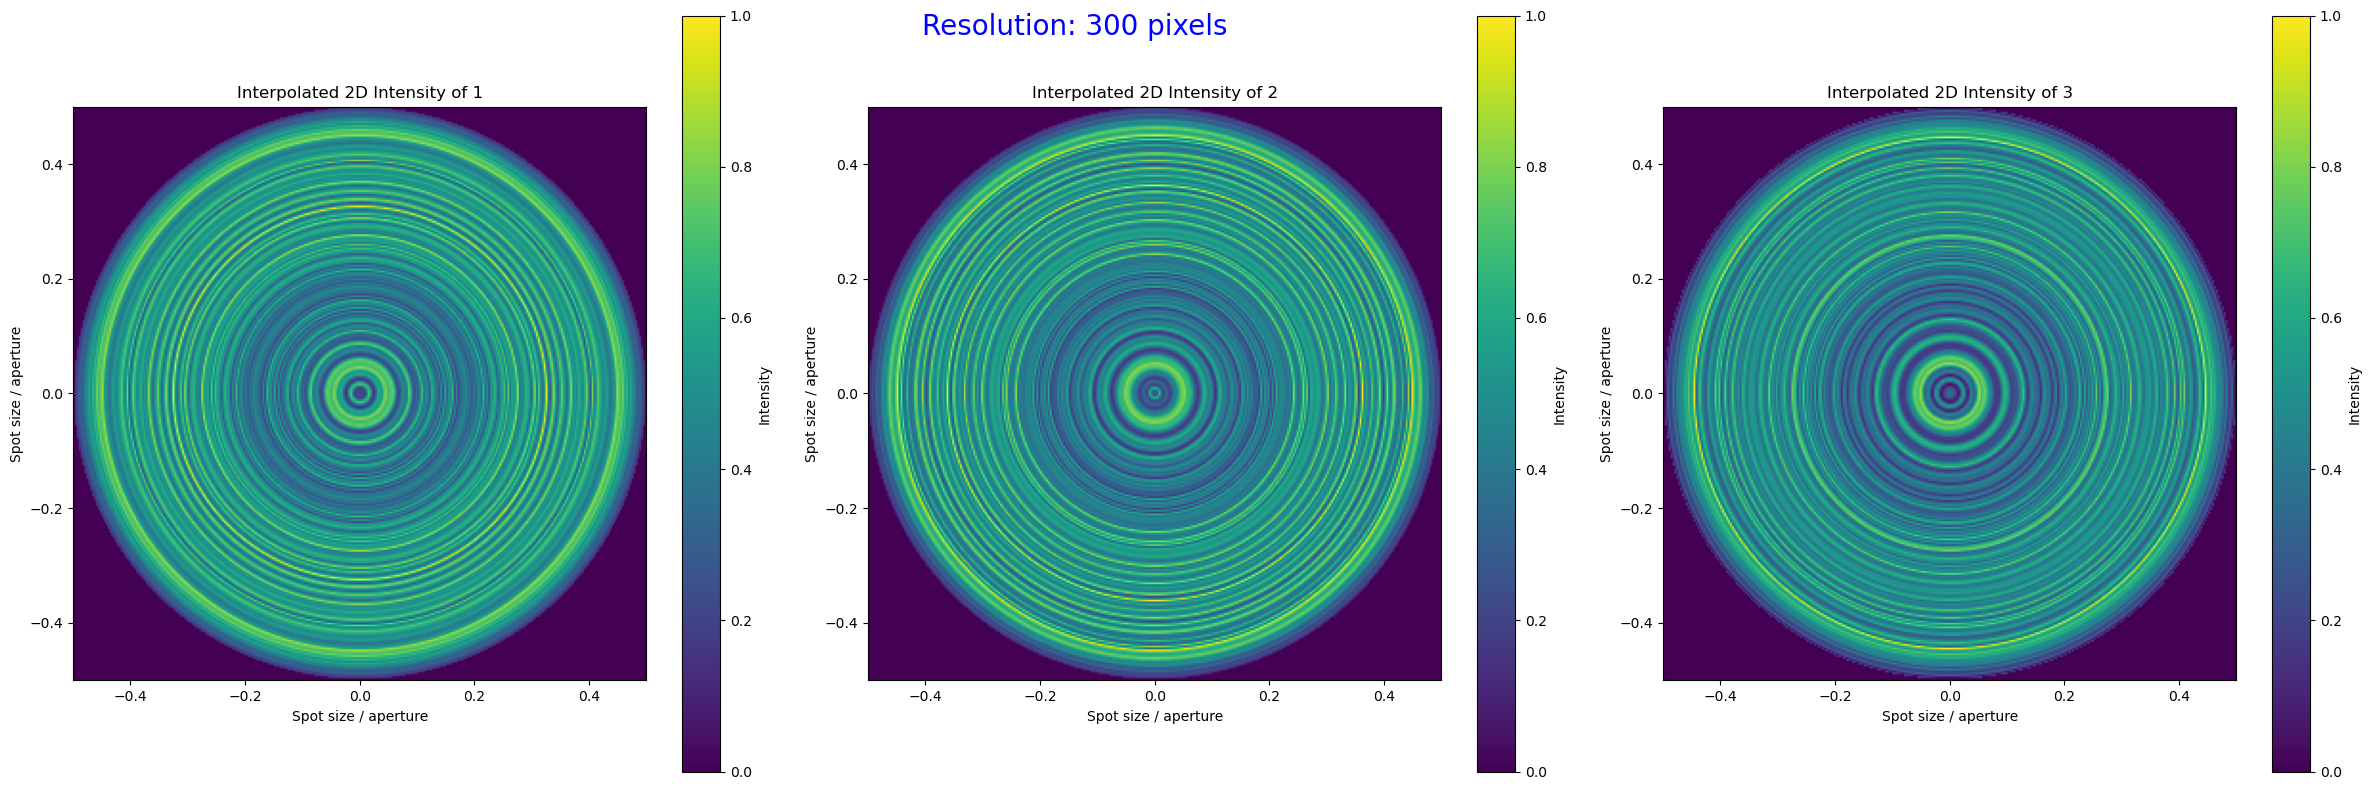

 78%|███████▊  | 7/9 [00:25<00:09,  4.97s/it]

Izyx_oa_max:0.12941077565102918


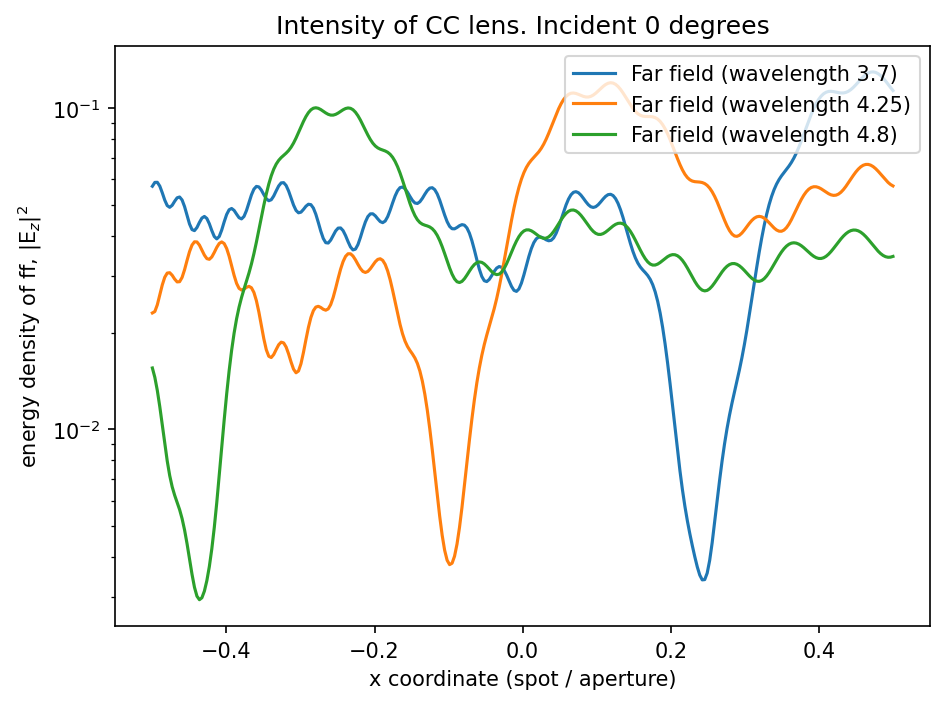

100%|██████████| 9/9 [00:46<00:00,  5.11s/it]

max Ez = 0.06375800439951805 , max Ey = 0.06565277125151113, max Ex = 5.039603145073604e-33
Wavelength 3.7 microns. Strehl_ratio for X_direction. I_0/I_max: 0.0137
Wavelength 3.7 microns. Strehl_ratio for Y_direction. I_0/I_max: 0.0177
Multiplication of them is 0.0002
Wavelength 4.25 microns. Strehl_ratio for X_direction. I_0/I_max: 0.0143
Wavelength 4.25 microns. Strehl_ratio for Y_direction. I_0/I_max: 0.0169
Multiplication of them is 0.0002
Wavelength 4.8 microns. Strehl_ratio for X_direction. I_0/I_max: 0.0155
Wavelength 4.8 microns. Strehl_ratio for Y_direction. I_0/I_max: 0.0162
Multiplication of them is 0.0003
avarage of Strehl_ratio across all wavelength is  0.00024487370822561574


In [1]:
import meep as mp
import numpy as np
import conf
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.interpolate import interp1d
from tqdm import tqdm
from scipy.special import j1

mp.Verbosity(3) # decrease amount of output
mp.quiet()

total = 9
progress_bar = tqdm(total=total)  # Инициализация прогресс-бара

# Simulation parameters for MEEP
increase_resolution = 3 # by default, that should be 1. This parameter multiply min_resolution
X_cell_size = conf.cell_X # Width of simulation doesn't affect on lense.
Y_cell_size = 4*1e3 # Aperture is 2 mm
cell = mp.Vector3(X_cell_size, Y_cell_size, 0)  # размер области симуляции
pml_layers = [mp.PML(thickness=conf.pml, direction=mp.X, side=mp.ALL)]
angle = 0 # in degrees

test_wavelength = conf.inc_wavelength
test_frec = 1/test_wavelength

sources_obj = conf.KvectorSource(frequency=test_frec, y = Y_cell_size, angle=angle)
sources = sources_obj.get_sources()

# All parameters related to the definition of geometry
D_spot = Y_cell_size # actual size in micrometers equal D of lens
M = 10 # the number of radial layers.
N_large_0order = 4
N = 2 # N must be even., 0 - 2 - 4 - 6 - 8 - 10
LIMIT_PRODUCT = 0.1 # Limitation 200 nm. Geometry can't be larger this size.

k = 2 * np.pi / conf.inc_wavelength # wave number
f = 10*1e3 # focal length 50 mm
Q = 300 # curve detailing. It has almost no effect on the result
w = 0.1 # 100 nm. The width of the gap between the curves

# Precompute radii
rt = np.sqrt(4 * f * (-np.pi / 2 + np.arange(1, M+1) * np.pi) / k)

"""
Нужно инициализировать матрицу с коэффициентами. Количество строк должно равняться количеству порядков rt.
Количество столбцов 2. В них записаны коэффициенты для левого и правого ограничения сектора. pl and pr. Для каждого порядка независимое значение pl and pr.
p(:,0) - pl
p(:,1) - pr
"""

initial_p = 0
p = np.full((len(rt), 2), initial_p)

# Define the function to integrate
def fun(x):
    return np.tan((k * x ** 2) / (4 * f))

def zero_derivative (m):
    calculation = np.sqrt((4 * f * m * np.pi)/k)
    return calculation

def get_y_section(y0, curves):
    """
    Получить срез кривых плоскостью Y = y0.

    :param y0: Значение Y для среза.
    :param curves: Список массивов с координатами кривых [(x1, y1), (x2, y2), ...].
    :return: Координата (x) для пересечения.
    """
    sections = np.zeros(shape=4)
    n=0
    for curve in curves:
        x_vals, y_vals = curve
        x_first_center = 0
        for i in range(len(y_vals) - 1):           
            y1, y2 = y_vals[i], y_vals[i + 1]
            x1, x2 = x_vals[i], x_vals[i + 1]         
            if y1 <= y0 <= y2 or y2 <= y0 <= y1:
                # Линейная интерполяция для x
                x_interp = x1 + (y0 - y1) * (x2 - x1) / (y2 - y1)
                if x_first_center != x_interp: sections[n] = x_interp
                x_first_center = x_interp
                n = n + 1
                
    return sections

def get_x_section(L_center = True, amount_centers = 10):
    # Main loop for layers
    if L_center:
        x_sections = np.zeros((M,amount_centers,4))
    else: x_sections = np.zeros((M,N+1,4))
    
    for m in range(M):
        rt0 = 0 if m == 0 else rt[m - 1] + 0.1
        dr = abs(rt0 - rt[m])
        dr_l = dr*p[m,0]
        dr_r = dr*p[m,1] + 0.001
        x = np.linspace(rt0+dr_l, rt[m]-dr_r, Q)
        # Compute y values by integration
        try:
            y = np.array([quad(fun, rt0, xi)[0] for xi in x])
        except Exception:
            y = 0
        
        yy = np.empty((amount_centers, 2), dtype=object)
        
        xt = x.copy()
        ip = np.argmin(y)
        y1 = y - y[ip]
        y11 = y1.copy()
        y2 = y11 - w
        
        print(f"Circle {m}")
        
        if L_center:
            SECTION = w*amount_centers
            #Здесь мы собираем все кривые принадлежащие данному порядку
            for n in range(amount_centers):
                curves = []
                yy[n, 0] = y1 + 2 * n * w # Верхняя кривая 
                yy[n, 1] = y2 + 2 * n * w # Нижняя кривая
                     
                # Формируем кривые
                curves.append((xt, yy[n,0]))
                curves.append((xt, yy[n,1]))
                
                # Получаем срез при Y = SECTION
                x_sections[m, n] = get_y_section(SECTION, curves)
                print(f"Section: {n} :", x_sections[m,n])   
            L_center = False
        
        else:
            SECTION = w*N
            for n in range(N):
                curves = []
                yy[n, 0] = y1 + 2 * n * w # Верхняя кривая 
                yy[n, 1] = y2 + 2 * n * w # Нижняя кривая
                     
                # Формируем кривые
                curves.append((xt, yy[n,0]))
                curves.append((xt, yy[n,1]))
                
                # Получаем срез при Y = SECTION
                x_sections[m, n] = get_y_section(SECTION, curves)
                print(f"Section: {n} :", x_sections[m,n])
    
    return x_sections

x_sections = get_x_section(False, N_large_0order) 

progress_bar.update(1)  # Обновление прогресса на 1 шаг
### End 1st PART

list_of_centers = []
list_of_widths = []

def get_width_first_order(x_sections):
    result = []
    for n in range(N_large_0order): 
        if x_sections[0, n, 0] == 0:
            # Добавляем width_first_order
            width_first_order = x_sections[0, n, 1] * 2
            result.append(width_first_order)
            return result  # Завершаем функцию сразу после нахождения значения
        else:
            # Вычисляем ширину и добавляем её в список
            width = abs(x_sections[0, n, 0] - x_sections[0, n, 1])
            result.append(width)

def get_centers_first_order(x_sections):
    result = []
    for n in range(N_large_0order):
        if x_sections[0, n, 0] == 0:
            first_center = 0
            result.append(first_center)
            return result
        else:
            another_center = abs(x_sections[0, n, 0] + x_sections[0, n, 1]) /2
            result.append(another_center)
            
def get_width_other_order(x_sections,m):
    result = []
    for n in range(N):
        if (x_sections[m,n,0] != 0) and (x_sections[m,n,1] == 0) and (x_sections[m,n+1,0] == 0):
            third = abs(x_sections[m,n,2] - x_sections[m,n,3])
            result.append(third)
            return result  
        if x_sections[m,n,0] == 0 or x_sections[m,n,0] == 0:
            continue
        if x_sections[m,n,2] != 0:
            first = abs(x_sections[m,n,0] - x_sections[m,n,2])
            result.append(first)       
        if x_sections[m,n,3] != 0:
            second = abs(x_sections[m,n,1] - x_sections[m,n,3])
            result.append(second)
          
def get_center_of_other_order(x_sections, m):
    result = []
    for n in range(N):
        if (x_sections[m,n,0] != 0) and (x_sections[m,n,1] == 0) and (x_sections[m,n+1,0] == 0):
            center = zero_derivative(m)
            result.append(center)
            return result         
        
        if x_sections[m,n,0] == 0 or x_sections[m,n,0] == 0:
            continue        
        if x_sections[m,n,2] != 0:
            first = (x_sections[m,n,0] + x_sections[m,n,2])/2
            result.append(first)
        if x_sections[m,n,3] != 0:
            second = (x_sections[m,n,1] + x_sections[m,n,3])/2
            result.append(second) 

for m in range(1,M):
    other_center = get_center_of_other_order(x_sections, m)
    other_width = get_width_other_order(x_sections, m)
    list_of_centers.append(other_center)
    list_of_widths.append(other_width)
    
list_of_centers.insert(0,get_centers_first_order(x_sections))
list_of_widths.insert(0,get_width_first_order(x_sections))

# A test to check the basic parameters. The length of the widths at each radius (in each order should be equal to the length of the centers)
for i in range (len(list_of_centers)):
    for j in range(len(list_of_centers[i])):
        if list_of_centers[i][j] != list_of_centers[i][j]:
            ValueError("List elements do not match")
print("Checked")

# Getters for widths and centers are ready, now you can assemble the geometry. The main centers are calculated as accurately as possible through derivatives. But the widths and centers of the additional sections are based on interpolation

progress_bar.update(1)  # Обновление прогресса на 1 шаг
### End 2nd PART
# Step 2. Infill meta-lense
geometry = []
geometry.append(mp.Block(
    material=conf.in_material,
    size=mp.Vector3(conf.in_sub, mp.inf, 0),
    center=mp.Vector3(conf.sub_center.x),
))

def flatten(lst):
    for item in lst:
        if isinstance(item, list):
            # Если элемент - это список, рекурсивно обрабатываем его
            yield from flatten(item)
        else:
            # Если элемент не список, возвращаем его
            yield item

# Getting all the items from the nested lists
flat_centers = list(flatten(list_of_centers))
flat_widths = list(flatten(list_of_widths))

# # Let's put it all into geometry now
for i in range(len(flat_centers)):
    if flat_widths[i] < LIMIT_PRODUCT:
        continue
    else:
        geometry.append(mp.Block(
            material=conf.at_material,
            size=mp.Vector3(x=conf.at_hei, y=flat_widths[i], z=0), 
            center=mp.Vector3(x=conf.at_center.x, y=flat_centers[i], z=0)
        ))
        
        geometry.append(mp.Block(
            material=conf.at_material,
            size=mp.Vector3(x=conf.at_hei, y=flat_widths[i], z=0),
            center=mp.Vector3(x=conf.at_center.x, y=-flat_centers[i], z=0)
        ))
        
progress_bar.update(1)  # Обновление прогресса на 1 шаг
### End 3d PART
sim = mp.Simulation(
    cell_size=cell,
    boundary_layers=pml_layers,
    geometry=geometry,
    sources=sources,
    k_point=sources_obj.get_k_vector(),
    resolution=conf.min_resolution * increase_resolution,
    # symmetries = [mp.Mirror(mp.Y)]
    
)

# Adding a near2far area
# Это поле определяет размер области по которой мы можем извлечь значения E and H 

near2far_region = sim.add_near2far(
    conf.inc_fcen,  # центральная частота
    conf.inc_df,      # ширина спектра
    conf.inc_nfreq, # дискретность частот
    mp.Near2FarRegion(center=conf.flux_center, size=mp.Vector3(y=D_spot)),
)

plt.figure(figsize=(1, 150))
sim.plot2D(
    output_plane = mp.Volume(center=mp.Vector3(0,0,0), size=mp.Vector3(cell[0], cell[1],0))
)
# plt.savefig("precomp_near_plot.png", dpi = 150)  # Сохранение изображения в файл
plt.show()  # Отображение изображения

progress_bar.update(1)  # Обновление прогресса на 1 шаг
### End 4th PART
# Running the simulation
conf.end_time(sim,angle)

progress_bar.update(1)  # Обновление прогресса на 1 шаг
### End 5th PART
def shift_y():
    if angle > 45:
        added_angle = 90 - angle
        add_shift_y = f*np.tan(np.radians(added_angle))
        shift_y = Y_cell_size + add_shift_y
    else:
        shift_y= (conf.source_center.x + f) * np.tan(np.radians(angle))
    return shift_y

def get_abscissa (D_spot, y, relation = "aperture"):
    """
    :param spot_size: область построения
    :param y: ордината
    :param toLimit: on/off relation to Airy disk
    :return: вектор нормированный либо на апертуру либо на площадь ограниченную дифракционным пределом
    """
    size_of_y = len(y)
    x_max = get_Airy_disk()
    x = np.zeros(size_of_y)
    if relation == "airy":
        x = np.linspace(-D_spot/2/x_max, D_spot/2/x_max, size_of_y)
    if relation == "aperture":
        x = np.linspace(-D_spot/2/Y_cell_size, D_spot/2/Y_cell_size, size_of_y)
    if relation == "abs":
        x = np.linspace(-D_spot/2, D_spot/2, size_of_y)
    return x

def get_Airy_disk ():
    x_max = 1.22 * conf.inc_wavelength * f / Y_cell_size
    return x_max

def plot_FF (I_ff, D_spot, relation = "aperture"):
    
    x_lable = ""
    
    if relation == "airy":
        x_lable = "/ limit_airy"
    if relation == "aperture":
        x_lable = "/ aperture"
    
    frequents_array = np.linspace(conf.inc_wavelength-conf.inc_dwavelength/2, conf.inc_wavelength+conf.inc_dwavelength/2, conf.inc_nfreq)
    plt.figure(dpi=150)
    # Перебираем столбцы (второй индекс матрицы)
    if len(frequents_array) == 1:
            plt.semilogy(
            get_abscissa(D_spot, I_ff, relation), I_ff, label=f"Far field (wavelength {frequents_array[0]})"
        )
    else:
        for i in range(I_ff.shape[1]):
            plt.semilogy(
                get_abscissa(D_spot, I_ff, relation), I_ff[:, i], label=f"Far field (wavelength {frequents_array[i]})"
            )
    
    plt.xlabel(f"x coordinate (spot {x_lable})")
    plt.ylabel(r"energy density of ff, |E$_z$|$^2$")
    plt.title(f"Intensity of CC lens. Incident {angle} degrees")
    plt.legend(loc="upper right")
    plt.tight_layout()
    plt.show()
# TODO: transform this into method
ff_res = conf.resolution_base/D_spot # resolution of the calculated field

# Calculating fields in the far zone on spot equals to spot_size. Focal Plane
far_field_fp = sim.get_farfields(
    near2far_region,
    ff_res,
    center=mp.Vector3(x=conf.flux_center[0] + f, y=shift_y()),
    size = mp.Vector3(y=D_spot)
)
Iz_far_field_fp = abs(far_field_fp["Ez"])**2
Iy_far_field_fp = abs(far_field_fp["Ey"])**2
Ix_far_field_fp = abs(far_field_fp["Ex"])**2
Izyx_fp = Iz_far_field_fp+Iy_far_field_fp+Ix_far_field_fp
print(f"Izyx_fp_max:{np.max(Izyx_fp)}")

plot_FF(I_ff = Izyx_fp, D_spot =  D_spot, relation = "aperture")
print(f"max Ez = {np.max(Iz_far_field_fp)} , max Ey = {np.max(Iy_far_field_fp)}, max Ex = {np.max(Ix_far_field_fp)}")

progress_bar.update(1)  # Обновление прогресса на 1 шаг
### End 6th PART
def get_psf(nfrec, I, D_spot):
    """
    :param nfrec(int): дискретность длин волн.
    :param I: массив с распределением интенсивностей
    :param D_spot: область на которой эти интенсивности определены
    :return: plots 
    """
    N = nfrec
    x = get_abscissa(D_spot, I[:,0], relation="aperture")
   
    # Создаём координатную сетку
    X, Y = np.meshgrid(x, x)
    # Преобразуем координаты в полярные
    R = np.sqrt(X**2 + Y**2)  # Радиальное расстояние
    # Визуализация 2D-распределения
    # Создаём фигуру с `N` подграфиками
    fig, axes = plt.subplots(1, N, figsize=(8 * N, 8))
    if N == 1:
        axes = [axes]  # Преобразуем в список для единообразной индексации
    
    print(f"shape of x is {x.shape} shape of I is {I[:,0].shape}")
    
    for i in range (N):
        # Интерполяция интенсивности
        interp_I_2d = interp1d(x, I[:,i], bounds_error=False, fill_value=0)
        
        I2d = interp_I_2d(R)
        # Нормализация интенсивности
        I2d_norm = (I2d - np.min(I2d)) / (np.max(I2d) - np.min(I2d))
        # Отображение 2D-распределения
        unit = 1  # Коэффициент
        extent = [x[0] * unit, x[-1] * unit, x[0] * unit, x[-1] * unit]

        im = axes[i].imshow(I2d_norm, cmap='viridis', extent=extent)
        axes[i].set_title(f"Interpolated 2D Intensity of {i+1}")
        axes[i].set_xlabel("Spot size / aperture")
        axes[i].set_ylabel("Spot size / aperture")
        fig.colorbar(im, ax=axes[i], label="Intensity")

    
    plt.tight_layout()
    plt.figtext(0.45, 0.95, "Resolution: {:} pixels".format(len(x)), 
                    ha="center", fontsize=20, color="blue")
    plt.show()

get_psf(conf.inc_nfreq, Izyx_fp, D_spot)

progress_bar.update(1)  # Обновление прогресса на 1 шаг
# End 7th PART
# Calculating fields in the far zone. Optical Axis
far_field_oa = sim.get_farfields(
    near2far_region,
    ff_res,
    center=mp.Vector3(x=conf.flux_center[0] + f, y=shift_y()),
    size = mp.Vector3(x=D_spot)
)
Iz_far_field_oa = abs(far_field_oa["Ez"])**2
Iy_far_field_oa = abs(far_field_oa["Ey"])**2
Ix_far_field_oa = abs(far_field_oa["Ex"])**2
Izyx_oa = Iz_far_field_oa + Iy_far_field_oa + Ix_far_field_oa
print(f"Izyx_oa_max:{np.max(Izyx_oa)}")

plot_FF(I_ff = Izyx_oa, D_spot =  D_spot, relation = "aperture")
print(f"max Ez = {np.max(Iz_far_field_oa)} , max Ey = {np.max(Iy_far_field_oa)}, max Ex = {np.max(Ix_far_field_oa)}")

progress_bar.update(1)  # Обновление прогресса на 1 шаг
### End 8th PART
frequents_array = np.linspace(conf.inc_wavelength-conf.inc_dwavelength/2, conf.inc_wavelength+conf.inc_dwavelength/2, conf.inc_nfreq)

def calculate_Strehl (D_spot, I_simualed):
    """
    :param D_spot: based on the general area of calculation
    :param I_simualed: Intensity of CC lens
    :return: Strehl_ratio based on Intensity 
    """ 
    # Let's count Strehl ratio
    # Find spot size for I_Airy 
    X = get_abscissa(D_spot, I_simualed, relation = "abs")
    Y = X
    r = np.sqrt(X**2 + Y**2)
    
    # Интенсивность Эйри
    k = 2 * np.pi / test_wavelength
    I_Airy = 4 * (j1(k * r) / (k * r)) ** 2
    I_Airy[np.isnan(I_Airy)] = 1  # Исправляем деление на 0
    I_Airy /= np.sum(I_Airy) # Нормируем
    
    # Интенсивность мета-линзы
    I_simualed /=np.sum(I_simualed)
    
    # Calculation
    I_max = np.max(I_Airy)
    I_0 = np.max(I_simualed)
    Strehl_ratio = I_0/I_max
    
    return Strehl_ratio

result = 0

for i in range (conf.inc_nfreq):
    print(f"Wavelength {frequents_array[i]} microns. Strehl_ratio for X_direction. I_0/I_max: {calculate_Strehl(D_spot, Izyx_fp[:,i]):.4f}")
    print(f"Wavelength {frequents_array[i]} microns. Strehl_ratio for Y_direction. I_0/I_max: {calculate_Strehl(D_spot, Izyx_oa[:,i]):.4f}")
    print(f"Multiplication of them is {calculate_Strehl(D_spot, Izyx_fp[:,i]) * calculate_Strehl(D_spot, Izyx_oa[:,i]):.4f}")
    result += calculate_Strehl(D_spot, Izyx_fp[:,i]) * calculate_Strehl(D_spot, Izyx_oa[:,i])
print ("avarage of Strehl_ratio across all wavelength is ", result/conf.inc_nfreq)

progress_bar.update(1)  # Обновление прогресса на 1 шаг
progress_bar.close()  # Закрытие прогресс-бара
### End 9th PART
#### End MEEP simulation

In [2]:
rt

array([206.15528128, 357.07142143, 460.97722286, 545.43560573,
       618.46584384, 683.73971656, 743.30343737, 798.43597113,
       850.        , 898.61003778])